In [3]:
from datasets import load_dataset

data = load_dataset("tanganke/stanford_cars", split="train")

image = data[0]["image"]
label = data[0]["label"]

/Users/ayush/.venvs/ml/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating spatter split: 100%|██████████| 8041/8041 [00:00<00:00, 43493.30 examples/s]


In [4]:
image,label

(<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=700x525>, 0)

<module 'matplotlib.pyplot' from '/Users/ayush/.venvs/ml/lib/python3.10/site-packages/matplotlib/pyplot.py'>

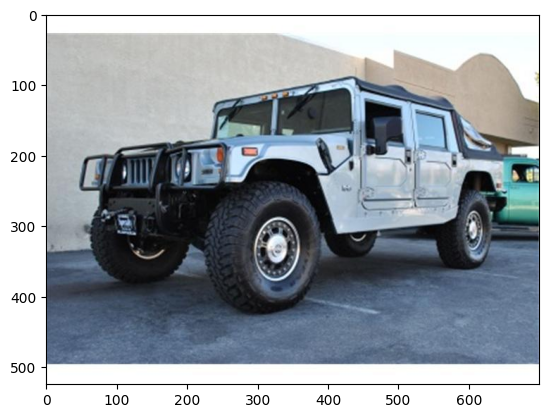

In [8]:
import matplotlib.pyplot as plt 

plt.imshow(image)
plt

In [16]:
data["image"]

Column([<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=700x525 at 0x12AFEA140>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=85x64 at 0x12AFEB880>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=94x71 at 0x12AFE8FD0>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=700x439 at 0x12AFEBCD0>, <PIL.Image.Image image mode=RGB size=250x188 at 0x12B7A0D60>, ...])

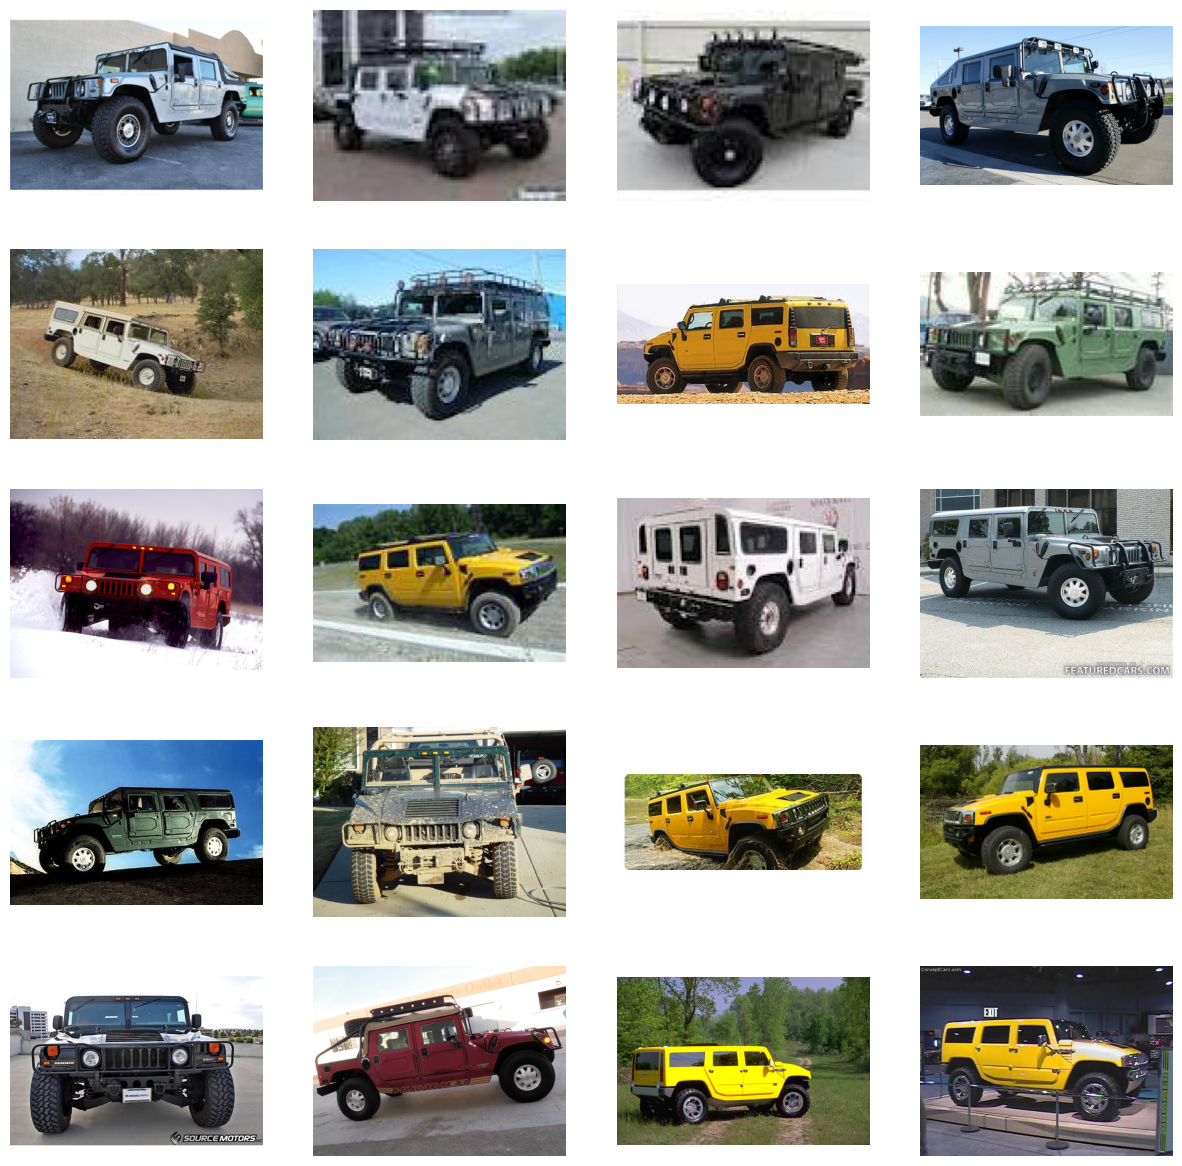

In [17]:
import torch
import torchvision
import matplotlib.pyplot as plt
import math

def show_images(dataset, num_samples=20, cols=4):
    plt.figure(figsize=(15, 15))

    for i, img in enumerate(dataset):
        if i == num_samples:
            break

        plt.subplot(math.ceil(num_samples / cols), cols, i + 1)

        image = img["image"]

        if isinstance(image, torch.Tensor):
            image = image.permute(1, 2, 0)

        plt.imshow(image)
        plt.axis("off")

    plt.show()

show_images(data)

In [18]:

import torch.nn.functional as F

def linear_beta_schedule(timesteps, start=0.0001, end=0.02):
    return torch.linspace(start, end, timesteps)

def get_index_from_list(vals, t, x_shape):
    """ 
    Returns a specific index t of a passed list of values vals
    while considering the batch dimension.
    """
    batch_size = t.shape[0]
    out = vals.gather(-1, t.cpu())
    return out.reshape(batch_size, *((1,) * (len(x_shape) - 1))).to(t.device)

def forward_diffusion_sample(x_0, t, device="cpu"):
    """ 
    Takes an image and a timestep as input and 
    returns the noisy version of it
    """
    noise = torch.randn_like(x_0)
    sqrt_alphas_cumprod_t = get_index_from_list(sqrt_alphas_cumprod, t, x_0.shape)
    sqrt_one_minus_alphas_cumprod_t = get_index_from_list(
        sqrt_one_minus_alphas_cumprod, t, x_0.shape
    )
    # mean + variance
    return sqrt_alphas_cumprod_t.to(device) * x_0.to(device) \
    + sqrt_one_minus_alphas_cumprod_t.to(device) * noise.to(device), noise.to(device)


# Define beta schedule
T = 300
betas = linear_beta_schedule(timesteps=T)

# Pre-calculate different terms for closed form
alphas = 1. - betas
alphas_cumprod = torch.cumprod(alphas, axis=0)
alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1. - alphas_cumprod)
posterior_variance = betas * (1. - alphas_cumprod_prev) / (1. - alphas_cumprod)

In [19]:
betas

tensor([1.0000e-04, 1.6656e-04, 2.3311e-04, 2.9967e-04, 3.6622e-04, 4.3278e-04,
        4.9933e-04, 5.6589e-04, 6.3244e-04, 6.9900e-04, 7.6555e-04, 8.3211e-04,
        8.9866e-04, 9.6522e-04, 1.0318e-03, 1.0983e-03, 1.1649e-03, 1.2314e-03,
        1.2980e-03, 1.3645e-03, 1.4311e-03, 1.4977e-03, 1.5642e-03, 1.6308e-03,
        1.6973e-03, 1.7639e-03, 1.8304e-03, 1.8970e-03, 1.9635e-03, 2.0301e-03,
        2.0967e-03, 2.1632e-03, 2.2298e-03, 2.2963e-03, 2.3629e-03, 2.4294e-03,
        2.4960e-03, 2.5625e-03, 2.6291e-03, 2.6957e-03, 2.7622e-03, 2.8288e-03,
        2.8953e-03, 2.9619e-03, 3.0284e-03, 3.0950e-03, 3.1615e-03, 3.2281e-03,
        3.2946e-03, 3.3612e-03, 3.4278e-03, 3.4943e-03, 3.5609e-03, 3.6274e-03,
        3.6940e-03, 3.7605e-03, 3.8271e-03, 3.8936e-03, 3.9602e-03, 4.0268e-03,
        4.0933e-03, 4.1599e-03, 4.2264e-03, 4.2930e-03, 4.3595e-03, 4.4261e-03,
        4.4926e-03, 4.5592e-03, 4.6258e-03, 4.6923e-03, 4.7589e-03, 4.8254e-03,
        4.8920e-03, 4.9585e-03, 5.0251e-

In [ ]:
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 64
BATCH_SIZE = 128

def load_transformed_dataset(dataset):
    data_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Lambda(lambda t: (t * 2) - 1)
    ])

    class TransformedDataset(torch.utils.data.Dataset):
        def __init__(self, dataset, transform):
            self.dataset = dataset
            self.transform = transform

        def __len__(self):
            return len(self.dataset)

        def __getitem__(self, idx):
            image = self.dataset[idx]["image"]
            return self.transform(image.convert("RGB"))

    return TransformedDataset(dataset, data_transform)


def show_tensor_image(image):
    reverse_transforms = transforms.Compose([
        transforms.Lambda(lambda t: (t + 1) / 2),
        transforms.Lambda(lambda t: t.permute(1, 2, 0)),
        transforms.Lambda(lambda t: t * 255.),
        transforms.Lambda(lambda t: t.cpu().numpy().astype(np.uint8)),
        transforms.ToPILImage(),
    ])

    if len(image.shape) == 4:
        image = image[0]

    plt.imshow(reverse_transforms(image))
    plt.axis("off")


# Use your existing dataset
transformed_data = load_transformed_dataset(data)

dataloader = DataLoader(
    transformed_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

# Test
batch = next(iter(dataloader))
show_tensor_image(batch)
plt.show()

ValueError: The original URL is broken so the StanfordCars dataset cannot be downloaded anymore.